In [1]:
]activate ../../../../

  Activating project at `~/UCLOneDrive/SpatialStructureInMicrobialCommunities/SSMCCode`

In [2]:
using Revise
includet("./base.jl")

In [22]:
using CairoMakie
using GLMakie
CairoMakie.activate!()
using Statistics, ColorSchemes

# Load data

In [5]:
m8dir = "./"

setup_df = load(joinpath(m8dir, "systems.jld2"), "pde_df")
smd = load(joinpath(m8dir, "systems.jld2"), "metadata")
df = collect_pde_runs(joinpath(m8dir, "data"))

# extinct strains were dropped at setup, so Ns varies by system and the hss is
# carried per row in the setup file
df.Ns = [get_Ns(setup_df.params[i])[1] for i in df.pde_df_row]
df.B_hss = [sum(setup_df.ode_hss[i][1:ns]) for (i, ns) in zip(df.pde_df_row, df.Ns)]
T = df.T[1]

@printf("%d/%d rows, retcodes %s\n", nrow(df), nrow(setup_df),
    string(sort(unique(string.(df.retcode)))))
@show smd.ps T length(unique(df.gdf_row));

40/40 rows, retcodes ["MaxTime", "Success"]
smd.ps = [0.1, 1.0]
T = 1.0e8
length(unique(df.gdf_row)) = 20

# Getting the semi-coarse-grained space-time series

In [17]:
df.series_t = Vector{Vector{Float64}}(undef, nrow(df))
df.series_N = Vector{Vector{Vector{Float64}}}(undef, nrow(df))
df.series_I = Vector{Vector{Vector{Float64}}}(undef, nrow(df))
df.series_R = Vector{Vector{Vector{Float64}}}(undef, nrow(df))

@showprogress for i in 1:nrow(df)
    p = setup_df.params[df.pde_df_row[i]]
    Ns = df.Ns[i]
    nr = size(p.c, 2)

    # influx resource, and the other resources some strain consumes
    j0 = findfirst(K -> K > 0, p.K)
    crossfed = Int[]
    for j in 1:nr
        if j != j0 && any(p.c[:, j] .> 0)
            push!(crossfed, j)
        end
    end

    ts, us = load_pde_states(joinpath(m8dir, "data"), df.pde_df_row[i])
    N = Vector{Float64}[]
    I = Vector{Float64}[]
    R = Vector{Float64}[]
    for u in us
        push!(N, vec(sum(u[1:Ns, :]; dims=1)))
        push!(I, u[Ns+j0, :])
        push!(R, vec(sum(u[Ns .+ crossfed, :]; dims=1)))
    end

    df.series_t[i] = ts
    df.series_N[i] = N
    df.series_I[i] = I
    df.series_R[i] = R
    us = nothing
    GC.gc()
end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:24

## Peak finding and extracting widths

In [46]:
fpp_kwargs = (; relheight=0.99)
df.peaks_N = [find_peaks_periodic(N[end]; fpp_kwargs...) for N in df.series_N]
df.peaks_I = [find_peaks_periodic(-I[end]; fpp_kwargs...) for I in df.series_I]
df.peaks_R = [find_peaks_periodic(R[end]; fpp_kwargs...) for R in df.series_R]

# mean peak width in x units (find_peaks_periodic gives gridpoints)
dx = df.L ./ df.sN
df.width_N = [mean(pk.widths) for pk in df.peaks_N] .* dx
df.width_I = [mean(pk.widths) for pk in df.peaks_I] .* dx
df.width_R = [mean(pk.widths) for pk in df.peaks_R] .* dx

df[:, [:pde_df_row, :gdf_row, :p, :L, :width_N, :width_I, :width_R]];

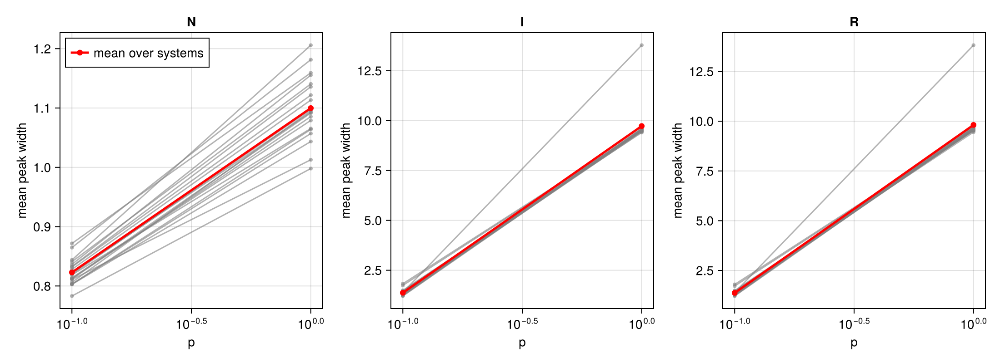

In [47]:
fig = Figure(size=(1100, 400))
for (j, (col, name)) in enumerate([(:width_N, "N"), (:width_I, "I"), (:width_R, "R")])
    ax = Axis(fig[1, j]; xscale=log10, xlabel="p", ylabel="mean peak width", title=name)
    for sys in unique(df.gdf_row)
        sdf = df[df.gdf_row .== sys, :]
        scatterlines!(ax, sdf.p, sdf[!, col]; color=(:gray, 0.6), markersize=6)
    end
    means = [mean(df[df.p .== p, col]) for p in smd.ps]
    scatterlines!(ax, smd.ps, means; color=:red, linewidth=2.5, label="mean over systems")
    j == 1 && axislegend(ax; position=:lt)
end
fig

## Vizualizing them and testing

In [26]:
fig = Figure(size=(1000, 750))
axN = Axis(fig[1, 1]; ylabel="N")
axIR = Axis(fig[2, 1]; xlabel="x", ylabel="concentration")
linkxaxes!(axN, axIR)

sg = SliderGrid(fig[3, 1],
    (label="row", range=1:nrow(df), startvalue=1),
    (label="t index", range=1:length(df.series_t[1]), startvalue=1),
)
sl_row, sl_t = sg.sliders

# the time slider's range follows the selected row
on(sl_row.value) do i
    sl_t.range[] = 1:length(df.series_t[i])
end

data = lift(sl_row.value, sl_t.value) do i, k
    k = min(k, length(df.series_t[i]))
    xs = range(0, df.L[i]; length=df.sN[i] + 1)[1:end-1]
    (; i, k, xs, N=df.series_N[i][k], I=df.series_I[i][k], R=df.series_R[i][k])
end

lines!(axN, lift(d -> Point2f.(d.xs, d.N), data); color=:black)
lines!(axIR, lift(d -> Point2f.(d.xs, d.I), data); label="I (influx)")
lines!(axIR, lift(d -> Point2f.(d.xs, d.R), data); label="R (cross-fed)")
axislegend(axIR)

Label(fig[0, 1], lift(d -> @sprintf("row %d, system %d, p = %g, t = %.4g",
    d.i, df.gdf_row[d.i], df.p[d.i], df.series_t[d.i][d.k]), data); tellwidth=false)

on(data) do _
    autolimits!(axN)
    autolimits!(axIR)
end

display(GLMakie.Screen(), fig)

GLMakie.Screen(...)




In [29]:
ps = smd.ps
nsys = length(unique(df.gdf_row))
fig = Figure(size=(520 * length(ps), 380 * nsys))
for i in 1:nrow(df)
    sys = df.gdf_row[i]
    col = findfirst(==(df.p[i]), ps)
    xs = range(0, df.L[i]; length=df.sN[i] + 1)[1:end-1]

    gl = GridLayout(fig[sys, col])
    axN = Axis(gl[1, 1]; ylabel="N", titlesize=10,
        title=@sprintf("row %d, system %d, p = %g, t = %.4g", i, sys, df.p[i], df.series_t[i][end]))
    axIR = Axis(gl[2, 1]; xlabel="x", ylabel="concentration")
    linkxaxes!(axN, axIR)
    hidexdecorations!(axN; grid=false)
    rowgap!(gl, 4)

    lines!(axN, xs, df.series_N[i][end]; color=:black)
    lines!(axIR, xs, df.series_I[i][end]; label="I (influx)")
    lines!(axIR, xs, df.series_R[i][end]; label="R (cross-fed)")
    if i == 1
        axislegend(axIR)
    end
end
rowgap!(fig.layout, 16)

Makie.save(joinpath(m8dir, "figures", "scg_final_states.pdf"), fig)

fig